## BACKTEST 2021

[BT] Training Days: 229, Testing Days: 62
[BT] Linear MAE: 111.80
[BT] Fold 1 MAE: 326.85
[BT] Fold 2 MAE: 55.16
[BT] Fold 3 MAE: 9.52
[BT] Fold 4 MAE: 35.25
[BT] Fold 5 MAE: 117.54

[BT] Random Forest CV MAE (mean): 108.86
[BT] Final Random Forest Test MAE: 93.24


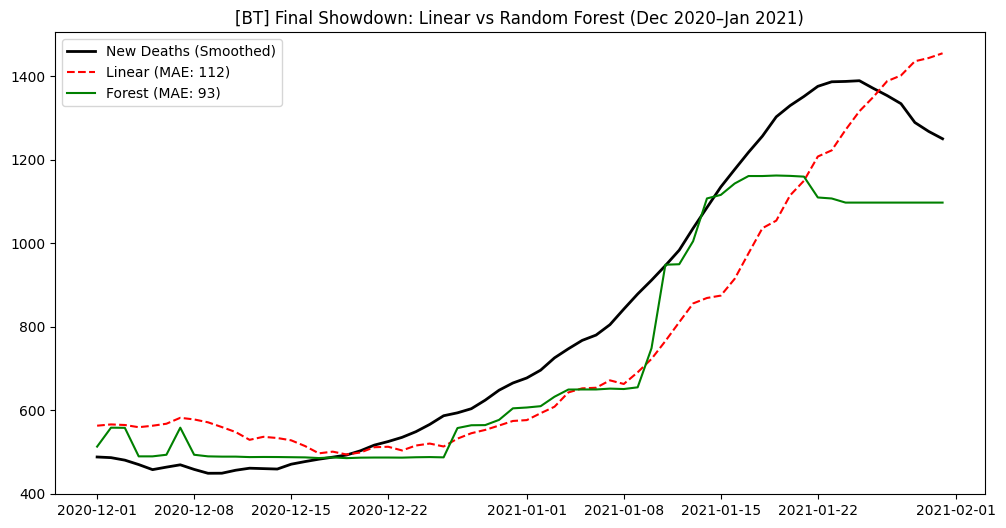

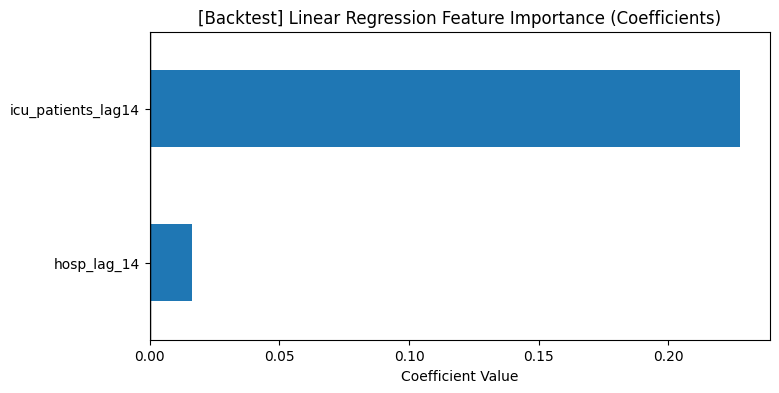

In [270]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit

# =========================
# BACKTEST (Jan 2021)
# =========================

# 1. LOAD & ENGINEER DATA (Recap)
bt_url = "data/compact.csv"
bt_df = pd.read_csv(bt_url)

bt_df['date'] = pd.to_datetime(bt_df['date'])
bt_df = bt_df[bt_df['country'] == 'United Kingdom'].set_index('date').sort_index()

# include Jan 31, 2022 since your test goes until then
bt_df = bt_df.loc['2020-01-01':'2022-01-31',
                  ['new_cases', 'new_deaths', 'hosp_patients',
                   'people_fully_vaccinated_per_hundred', 'stringency_index',
                   'reproduction_rate', 'icu_patients']]

# =========================
# Feature Engineering
# =========================


# Better than fillna(0) for these columns
bt_df['hosp_patients'] = bt_df['hosp_patients'].ffill().fillna(0)
bt_df['people_fully_vaccinated_per_hundred'] = (
    bt_df['people_fully_vaccinated_per_hundred']
      .ffill()
      .fillna(0)
)
bt_df['stringency_index'] = bt_df['stringency_index'].ffill()

bt_df['cases_lag_14'] = bt_df['new_cases'].shift(14)   #Cases 14 days before                  
bt_df['hosp_lag_7'] = bt_df['hosp_patients'].shift(7)  #hosp lag 7 days because it is more contributing than 14 days lag                  
bt_df['hosp_lag_14'] = bt_df['hosp_patients'].shift(14)                  
bt_df['cases_smooth_7lag14'] = bt_df['new_cases'].rolling(7).mean().shift(14) #new_smoothed cases with lag of 14 days
bt_df['cases_smooth_7'] = bt_df['new_cases'].rolling(7).mean().shift(1) #new_smoothed cases with lag of 1 days
bt_df['icu_patients_lag14'] = bt_df['icu_patients'].shift(14) #icu patients with a lag of 14 days

# a smoothed view, but NO leakage : 

bt_df['deaths_smooth_7'] = bt_df['new_deaths'].rolling(7).mean().shift(1) #shifted 1 to avoid present day info
bt_df['icu_patients7'] = bt_df['icu_patients'].rolling(7).mean().shift(1) #shifted 1 to avoid present day info


# --------------------------
# 2. SPLIT DATA (Time-Based)
# --------------------------

bt_cutoff = '2021-01-01'

bt_features = [
    # 'cases_lag_14',
    # 'cases_smooth_7lag14',
    # 'cases_smooth_7',
    'hosp_lag_14',
    'icu_patients_lag14',
   
]

bt_target = "deaths_smooth_7"

# IMPORTANT: use the df with NA rows removed for modeling
bt_df_model = bt_df.dropna(subset=bt_features + [bt_target])

#Backtest window: training up to Nov 30 2020, test Dec 1 2020 -> Jan 31 2021

bt_train = bt_df_model[bt_df_model.index < "2020-12-01"]
bt_test  = bt_df_model.loc["2020-12-01":"2021-01-31"]

bt_X_train, bt_y_train = bt_train[bt_features], bt_train[bt_target]
bt_X_test, bt_y_test   = bt_test[bt_features], bt_test[bt_target]

print(f"[BT] Training Days: {len(bt_X_train)}, Testing Days: {len(bt_X_test)}")

# Step A: Baseline (Linear Regression)
bt_lr = LinearRegression()
bt_lr.fit(bt_X_train, bt_y_train)

bt_pred_lr = bt_lr.predict(bt_X_test)
bt_mae_lr = mean_absolute_error(bt_y_test, bt_pred_lr)

bt_lr_importance = pd.Series(
    bt_lr.coef_,
    index=bt_features
).sort_values()

print(f"[BT] Linear MAE: {bt_mae_lr:.2f}")
# -----------------------------------------------------------
# Step B: Random Forest with TimeSeries CV (NO leakage)
# -----------------------------------------------------------

bt_tscv = TimeSeriesSplit(n_splits=5)

bt_rf = RandomForestRegressor(
    n_estimators=1200,
    max_depth=5,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

bt_mae_scores = []
# -----------------------------------------------------------
# CV should happen on TRAIN only (so the "test" remains a true holdout)
# -----------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(bt_tscv.split(bt_X_train)):
    bt_X_tr, bt_X_val = bt_X_train.iloc[train_idx], bt_X_train.iloc[val_idx]
    bt_y_tr, bt_y_val = bt_y_train.iloc[train_idx], bt_y_train.iloc[val_idx]

    bt_rf.fit(bt_X_tr, bt_y_tr)
    bt_preds_val = bt_rf.predict(bt_X_val)

    bt_mae = mean_absolute_error(bt_y_val, bt_preds_val)
    bt_mae_scores.append(bt_mae)

    print(f"[BT] Fold {fold+1} MAE: {bt_mae:.2f}")

print(f"\n[BT] Random Forest CV MAE (mean): {np.mean(bt_mae_scores):.2f}")

# Fit RF on full TRAIN, evaluate on TEST
bt_rf.fit(bt_X_train, bt_y_train)
bt_pred_rf = bt_rf.predict(bt_X_test)
bt_mae_rf = mean_absolute_error(bt_y_test, bt_pred_rf)

print(f"[BT] Final Random Forest Test MAE: {bt_mae_rf:.2f}")



# -----------------------------------------------------------
# Visualization
# -----------------------------------------------------------

plt.figure(figsize=(12, 6))
plt.plot(bt_test.index, bt_y_test, color="black", label="New Deaths (Smoothed)", linewidth=2)
plt.plot(bt_test.index, bt_pred_lr, color="red", linestyle="--", label=f"Linear (MAE: {bt_mae_lr:.0f})")
plt.plot(bt_test.index, bt_pred_rf, color="green", label=f"Forest (MAE: {bt_mae_rf:.0f})")
plt.title("[BT] Final Showdown: Linear vs Random Forest (Dec 2020–Jan 2021)")
plt.legend()
plt.show()

# ------------------------------------------------------------------------------------
# We check the importance of coefficients, using baseline LR and model the features.
# ------------------------------------------------------------------------------------


plt.figure(figsize=(8, 4))
bt_lr_importance.plot(kind="barh")
plt.title("[Backtest] Linear Regression Feature Importance (Coefficients)")
plt.xlabel("Coefficient Value")
plt.axvline(0, color="black", linewidth=1)
plt.show()





## FORECASTING


In [315]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# 1. LOAD & ENGINEER DATA (Recap)
url = "data/compact.csv"
df = pd.read_csv(url)
df['date'] = pd.to_datetime(df['date'])
df = df[df['country'] == 'United Kingdom'].set_index('date').sort_index()

# include Jan 31, 2022 since your test goes until then
df = df.loc['2020-01-01':'2022-01-31',
            ['new_cases', 'new_deaths', 'hosp_patients', 'people_fully_vaccinated_per_hundred','stringency_index','reproduction_rate','icu_patients','positive_rate']]

# Better than fillna(0) for these columns
df['hosp_patients'] = df['hosp_patients'].ffill()
df['people_fully_vaccinated_per_hundred'] = df['people_fully_vaccinated_per_hundred'].ffill()

# Feature Engineering
df['cases_lag_14'] = df['new_cases'].shift(14)                # The Driver
df['hosp_lag_7'] = df['hosp_patients'].shift(7)               # Leading Indicator
df['hosp_lag_14'] = df['hosp_patients'].shift(14)             # Leading Indicator
df['cases_smooth_7'] = df['new_cases'].rolling(7).mean().shift(14)     # The Trend
# df['velocity'] = df['cases_smooth_7'].pct_change(7)           # The Physics
# df['is_weekend'] = df.index.dayofweek.isin([5, 6]).astype(int)# The Cycle
# df['day_of_week'] = df.index.dayofweek                        # The Cycle

# df['icu_patients_lag7']= df['icu_patients'].shift(7)

#  (if you still want a smoothed view, but NO leakage):
df['deaths_smooth_7'] = df['new_deaths'].rolling(7).mean().shift(1)    
df['icu_patients7'] = df['icu_patients'].rolling(7).mean()

df = df.dropna()


# 2. SPLIT DATA (Time-Based)
# --------------------------
cutoff = '2022-01-01'

features = ['cases_lag_14', 'cases_smooth_7', 'hosp_lag_14','stringency_index','hosp_lag_7','people_fully_vaccinated_per_hundred']
# features = ['cases_lag_14', 'cases_smooth_7']

target = "deaths_smooth_7"  # assignment target replaced with smoothened

df_model = df.dropna(subset=features + [target])

train = df[df.index < "2021-12-01"]
test  = df["2021-12-01":"2022-01-31"]

# using target, not target_smooth
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print(f"Training Days: {len(X_train)}, Testing Days: {len(X_test)}")





Training Days: 325, Testing Days: 62


Fold 1 MAE: 161.43
Fold 2 MAE: 78.88
Fold 3 MAE: 51.51
Fold 4 MAE: 22.84
Fold 5 MAE: 18.83

Random Forest CV MAE (mean): 66.70
Final Random Forest Test MAE: 19.15


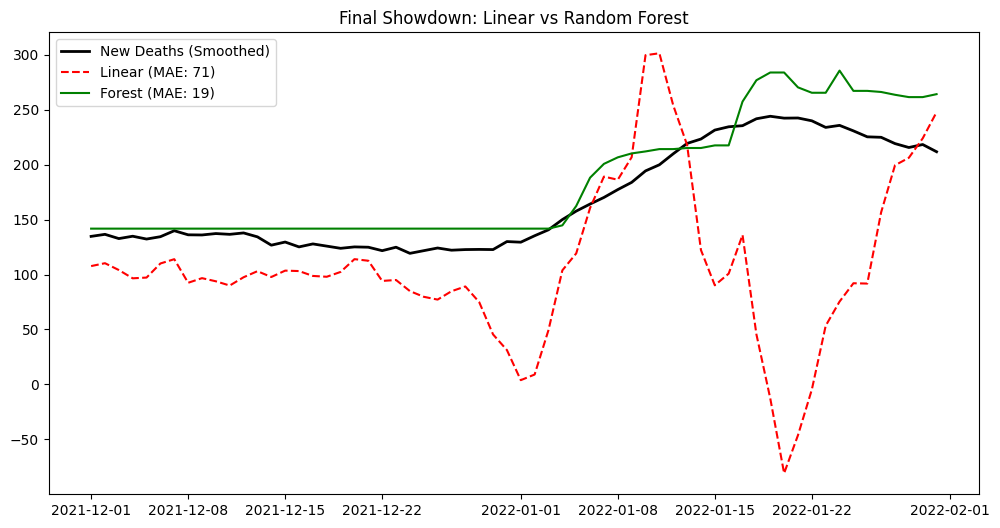

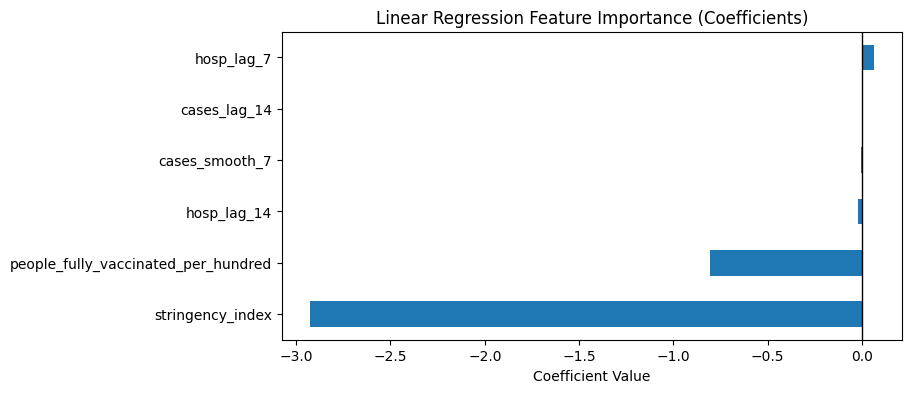

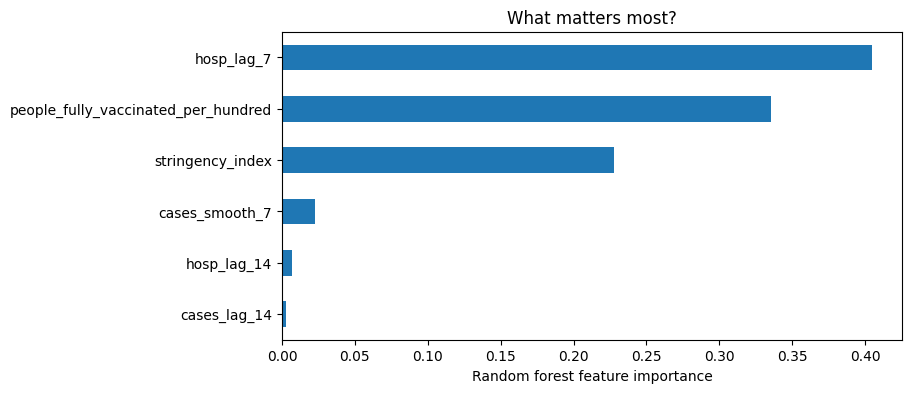

In [318]:
# Step A: Baseline (Linear Regression)
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
mae_lr = mean_absolute_error(y_test, pred_lr)


lr_importance = pd.Series(
    lr.coef_,
    index=features
).sort_values()


# # Step B: Random Forest
# rf = RandomForestRegressor(
#     n_estimators=100,
#     max_depth=3,
#     min_samples_leaf=5,
#     min_samples_split=5,
#     random_state=42,
# )
# rf.fit(X_train, y_train)
# pred_rf = rf.predict(X_test)
# mae_rf = mean_absolute_error(y_test, pred_rf)

# print(f"Linear MAE:        {mae_lr:.2f}")
# # print(f"Decision Tree MAE: {mae_dt:.2f}")
# print(f"Random Forest MAE: {mae_rf:.2f}")


from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

tscv = TimeSeriesSplit(n_splits=5)

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

mae_scores = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    rf.fit(X_train, y_train)
    preds = rf.predict(X_val)

    mae = mean_absolute_error(y_val, preds)
    mae_scores.append(mae)

    print(f"Fold {fold+1} MAE: {mae:.2f}")

print(f"\nRandom Forest CV MAE (mean): {np.mean(mae_scores):.2f}")

rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
mae_rf = mean_absolute_error(y_test, pred_rf)

print(f"Final Random Forest Test MAE: {mae_rf:.2f}")





# Visualization
plt.figure(figsize=(12, 6))
plt.plot(test.index, y_test, color="black", label="New Deaths (Smoothed)", linewidth=2)
plt.plot(test.index, pred_lr, color="red", linestyle="--", label=f"Linear (MAE: {mae_lr:.0f})")
plt.plot(test.index, pred_rf, color="green", label=f"Forest (MAE: {mae_rf:.0f})")
# plt.axvline(
#     pd.Timestamp("2021-01-01"),  # change year if needed
#     color="blue",
#     linestyle=":",
#     linewidth=2,
#     label="Cutoff: Jan 1"
# )
plt.title("Final Showdown: Linear vs Random Forest")
plt.legend()
plt.show()


plt.figure(figsize=(8, 4))
lr_importance.plot(kind="barh")
plt.title("Linear Regression Feature Importance (Coefficients)")
plt.xlabel("Coefficient Value")
plt.axvline(0, color="black", linewidth=1)
plt.show()



# Opening the black box
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 4))
importances.plot(kind="barh")  
plt.title("What matters most?")
plt.xlabel("Random forest feature importance")
plt.show()

In [325]:
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor

tscv = TimeSeriesSplit(n_splits=5)

xgb_params = dict(
    n_estimators=900,
    learning_rate=0.10,
    max_depth=5,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1
)

mae_scores = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    xgb = XGBRegressor(**xgb_params)
    xgb.fit(X_tr, y_tr)

    pred_val = xgb.predict(X_val)
    mae = mean_absolute_error(y_val, pred_val)
    mae_scores.append(mae)

    print(f"Fold {fold+1} MAE: {mae:.2f}")

print(f"\nXGBoost CV MAE (mean): {np.mean(mae_scores):.2f}")
print(f"XGBoost CV MAE (std):  {np.std(mae_scores):.2f}")


xgb = XGBRegressor(**xgb_params)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)
mae_xgb = mean_absolute_error(y_test, pred_xgb)

print(f"XGBoost Test MAE: {mae_xgb:.2f}")




Fold 1 MAE: 112.37
Fold 2 MAE: 171.67
Fold 3 MAE: 20.03
Fold 4 MAE: 10.15
Fold 5 MAE: 47.54

XGBoost CV MAE (mean): 72.35
XGBoost CV MAE (std):  61.14
XGBoost Test MAE: 48.77


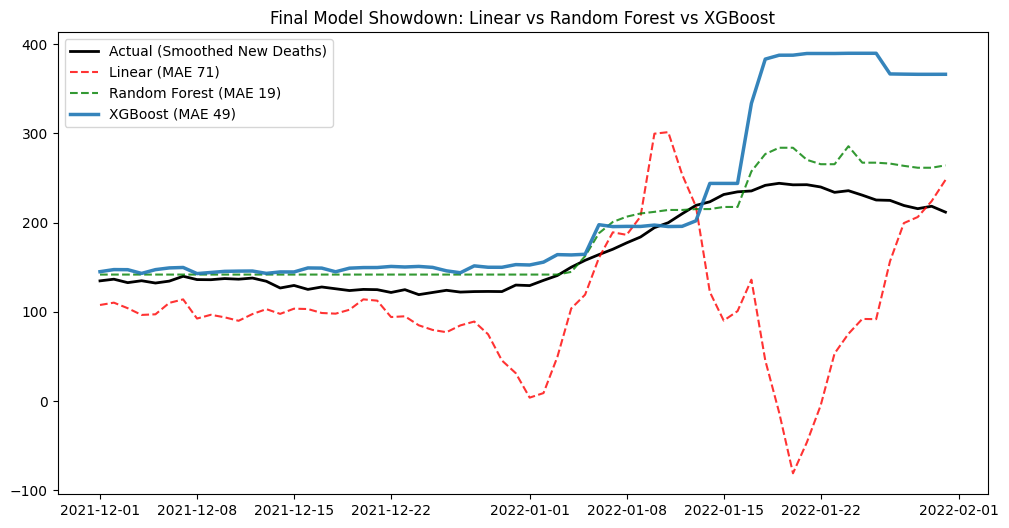

In [326]:
plt.figure(figsize=(12, 6))

plt.plot(
    test.index,
    y_test,
    color="black",
    linewidth=2,
    label="Actual (Smoothed New Deaths)"
)

plt.plot(
    test.index,
    pred_lr,
    color="red",
    linestyle="--",
    alpha=0.8,
    label=f"Linear (MAE {mae_lr:.0f})"
)

plt.plot(
    test.index,
    pred_rf,
    color="green",
    linestyle="--",
    alpha=0.8,
    label=f"Random Forest (MAE {mae_rf:.0f})"
)

plt.plot(
    test.index,
    pred_xgb,
    linewidth=2.5,
    alpha=0.9,
    label=f"XGBoost (MAE {mae_xgb:.0f})"
)

plt.title("Final Model Showdown: Linear vs Random Forest vs XGBoost")
plt.legend()
plt.show()


# RANDOM FOREST IS BEST
## SET FOR DEPLOYMENT
### DOWNLOAD THE CSV

In [324]:


pred_rf = rf.predict(X_test)

jan_mask = (X_test.index >= "2022-01-01") & (X_test.index <= "2022-01-31")

jan_dates = X_test.index[jan_mask]
jan_predictions = pred_rf[jan_mask]

final_predictions = pd.DataFrame({
    "Date": jan_dates,
    "Region": "United Kingdom",
    "Predicted deaths": jan_predictions,
    "Actual deaths": y_test.loc[jan_dates].values
})

final_predictions["Predicted deaths"] = (
    final_predictions["Predicted deaths"].round(0).astype(int)
)

final_predictions.to_csv("UKjan_2022_predicted_deaths,UK.csv", index=False)

print(final_predictions.head())
print(final_predictions.tail())
print(len(final_predictions))  # should be 31 (or fewer if early Jan dropped)


print("File downloaded successfully!")

        Date          Region  Predicted deaths  Actual deaths
0 2022-01-01  United Kingdom               142     129.428571
1 2022-01-02  United Kingdom               142     135.285714
2 2022-01-03  United Kingdom               142     140.714286
3 2022-01-04  United Kingdom               145     150.000000
4 2022-01-05  United Kingdom               162     157.714286
         Date          Region  Predicted deaths  Actual deaths
26 2022-01-27  United Kingdom               266     224.857143
27 2022-01-28  United Kingdom               264     219.142857
28 2022-01-29  United Kingdom               261     215.571429
29 2022-01-30  United Kingdom               261     218.285714
30 2022-01-31  United Kingdom               264     211.714286
31
File downloaded successfully!
